# NB1 — DeepLabV3 Semantic Segmentation (5-Epoch Commented Test Version)

This notebook trains and evaluates **DeepLabV3-ResNet50** for the Moroccan landing-site semantic segmentation dataset.

NB1 does **not** recreate the train/validation/test split. It loads the authoritative split and reusable preprocessing module exported by NB0.

Main responsibilities:

1. Load NB0's `all_splits.csv`.
2. Import NB0's `segmentation_common.py`.
3. Train DeepLabV3 for at least 50 epochs.
4. Report mIoU, per-class IoU, pixel accuracy, mean pixel accuracy, Dice/F1, and confusion matrix.
5. Save metrics and qualitative predictions for NB3's final comparison.

> This copy is prepared for a short 5-epoch test run. For the final assignment run, change `"epochs": 5` back to `"epochs": 50`.


## Before running this notebook on Kaggle

Add these inputs:

- the raw dataset: **Moroccan Landing Site Segmentation V2**
- the saved output from NB0, containing:
  - `NB0_outputs/splits/all_splits.csv`
  - `NB0_outputs/encoded_masks/`
  - `NB0_outputs/common/segmentation_common.py`
  - `NB0_outputs/metadata/`



In [1]:
# Cell purpose: import all libraries, define global constants, choose GPU/CPU, and create the NB1 output folder.
# How it works:
# - /kaggle/input contains the raw dataset and NB0 output that you add from the Kaggle side panel.
# - /kaggle/working is where this notebook saves NB1 outputs.
# - seed_everything() keeps the experiment more reproducible.

import copy
import importlib
import json
import math
import os
import random
import sys
import textwrap
import time
from contextlib import nullcontext
from datetime import datetime, timezone
from pathlib import Path

os.environ.setdefault("NO_ALBUMENTATIONS_UPDATE", "1")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from IPython.display import Markdown, display
from PIL import Image
from torch.utils.data import DataLoader
from torchvision.models.segmentation import (
    DeepLabV3_ResNet50_Weights,
    deeplabv3_resnet50,
)
from torchvision.models.segmentation.deeplabv3 import DeepLabHead, FCNHead
from tqdm.auto import tqdm


SEED = 42
IMAGE_SIZE = 256
NUM_CLASSES = 2
CLASS_ID_TO_NAME = {
    0: "background",
    1: "landing_site",
}

INPUT_ROOT = Path("/kaggle/input")
WORK_ROOT = Path("/kaggle/working")
OUTPUT_ROOT = WORK_ROOT / "NB1_outputs"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)


def seed_everything(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True


seed_everything(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

print("Device:", DEVICE)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("Output directory:", OUTPUT_ROOT)


Device: cuda
CUDA available: True
GPU: Tesla T4
Output directory: /kaggle/working/NB1_outputs


## 1. Locate NB0 outputs and raw dataset

This cell finds the shared split manifest, the reusable NB0 preprocessing module, and the raw dataset root.


In [2]:
# Cell purpose: find the two required inputs automatically.
# What it searches for:
# - NB0 split file: all_splits.csv
# - NB0 reusable preprocessing file: segmentation_common.py
# - raw dataset folder: dataset/training/images, dataset/training/masks, dataset/testing/images, dataset/testing/masks
# If one of these is missing, the notebook stops early with a clear message.

print("Attached Kaggle inputs:")
for path in sorted(INPUT_ROOT.iterdir()):
    print(" -", path)


split_candidates = sorted(INPUT_ROOT.rglob("all_splits.csv"))
assert split_candidates, (
    "NB0 all_splits.csv was not found. "
    "Add the saved NB0 notebook output as a Kaggle input."
)

# Prefer NB0 output tree if more than one file exists.
split_candidates = sorted(
    split_candidates,
    key=lambda p: (
        "NB0_outputs" not in str(p),
        len(str(p)),
    ),
)
SPLIT_FILE = split_candidates[0]
NB0_OUTPUT_ROOT = SPLIT_FILE.parents[1]


common_candidates = sorted(INPUT_ROOT.rglob("segmentation_common.py"))
assert common_candidates, (
    "NB0 segmentation_common.py was not found. "
    "The corrected NB0 output should include NB0_outputs/common/segmentation_common.py."
)

common_candidates = sorted(
    common_candidates,
    key=lambda p: (
        "NB0_outputs" not in str(p),
        len(str(p)),
    ),
)
COMMON_DIR = common_candidates[0].parent


dataset_roots = []
for candidate in INPUT_ROOT.rglob("dataset"):
    if (
        (candidate / "training" / "images").is_dir()
        and (candidate / "training" / "masks").is_dir()
        and (candidate / "testing" / "images").is_dir()
        and (candidate / "testing" / "masks").is_dir()
    ):
        dataset_roots.append(candidate)

assert dataset_roots, (
    "Raw Moroccan landing-site dataset was not found in /kaggle/input."
)

DATA_ROOT = sorted(dataset_roots, key=lambda p: len(str(p)))[0]

print("\nNB0 split file:", SPLIT_FILE)
print("NB0 output root:", NB0_OUTPUT_ROOT)
print("NB0 common module:", COMMON_DIR / "segmentation_common.py")
print("Raw dataset root:", DATA_ROOT)


Attached Kaggle inputs:
 - /kaggle/input/datasets
 - /kaggle/input/notebooks

NB0 split file: /kaggle/input/notebooks/happysruti/438-ass-1/NB0_outputs/splits/all_splits.csv
NB0 output root: /kaggle/input/notebooks/happysruti/438-ass-1/NB0_outputs
NB0 common module: /kaggle/input/notebooks/happysruti/438-ass-1/NB0_outputs/common/segmentation_common.py
Raw dataset root: /kaggle/input/datasets/happysruti/moroccan-landing-site-segmentation-v2/Moroccan Aircraft Emergency Landing Sites Semantic Segmentation Dataset/dataset


## 2. Load the split manifest

NB1 must use exactly the same split created by NB0. This notebook only validates and consumes the split.


In [3]:
# Cell purpose: load NB0's official train/validation/test split.
# Important idea:
# - NB1 must NOT create a new split.
# - all_splits.csv already contains a 'split' column with train, val, and test rows.
# - This cell checks counts, required columns, leakage-safe group boundaries, and file paths.

# Read the one CSV that contains train, validation, and test rows.
split_df = pd.read_csv(SPLIT_FILE)

required_columns = {
    "image_id",
    "split",
    "image_relpath",
    "encoded_mask_relpath",
    "group_id",
}
missing_columns = required_columns - set(split_df.columns)
assert not missing_columns, f"NB0 manifest is missing columns: {missing_columns}"

assert len(split_df) == 2090, f"Expected 2,090 samples, found {len(split_df)}"
assert split_df["image_id"].is_unique, "Duplicate image_id values found."
assert set(split_df["split"]) == {"train", "val", "test"}

expected_counts = {
    "train": 1416,
    "val": 314,
    "test": 360,
}
actual_counts = split_df["split"].value_counts().to_dict()
assert actual_counts == expected_counts, (
    f"Unexpected split counts. Expected {expected_counts}, found {actual_counts}"
)

# Group-level leakage boundary check.
group_split_counts = split_df.groupby("group_id")["split"].nunique()
assert group_split_counts.max() == 1, "A related group crosses split boundaries."

# Resolve paths so failures appear before training starts.
split_df["resolved_image_path"] = split_df["image_relpath"].apply(
    lambda relpath: str(DATA_ROOT / relpath)
)
split_df["resolved_mask_path"] = split_df["encoded_mask_relpath"].apply(
    lambda relpath: str(NB0_OUTPUT_ROOT / relpath)
)

missing_images = [
    path for path in split_df["resolved_image_path"]
    if not Path(path).exists()
]
missing_masks = [
    path for path in split_df["resolved_mask_path"]
    if not Path(path).exists()
]
assert not missing_images, f"Some raw images could not be resolved: {missing_images[:3]}"
assert not missing_masks, f"Some encoded masks could not be resolved: {missing_masks[:3]}"

# Split the single manifest table into three dataframes for model training/evaluation.
train_df = split_df[split_df["split"] == "train"].reset_index(drop=True)
val_df = split_df[split_df["split"] == "val"].reset_index(drop=True)
test_df = split_df[split_df["split"] == "test"].reset_index(drop=True)

display(pd.DataFrame({
    "split": ["train", "validation", "test"],
    "samples": [len(train_df), len(val_df), len(test_df)],
    "percent": [
        100 * len(train_df) / len(split_df),
        100 * len(val_df) / len(split_df),
        100 * len(test_df) / len(split_df),
    ],
}))

print("Shared NB0 split loaded successfully. No new split was generated in NB1.")


,split,samples,percent
0,train,1416,67.751196
1,validation,314,15.023923
2,test,360,17.224880


Shared NB0 split loaded successfully. No new split was generated in NB1.


## 3. Import NB0 preprocessing and create datasets

The dataset class and augmentation transforms come from NB0's small reusable module, not from the full NB0 notebook.


In [4]:
# Cell purpose: import NB0's shared preprocessing code and build PyTorch datasets/loaders.
# What comes from NB0:
# - LandingSiteDataset: reads images and encoded 0/1 masks.
# - build_train_transform(): synchronized training augmentations.
# - build_eval_transform(): deterministic validation/test preprocessing.
# DataLoader then batches the dataset so the model can train efficiently.

if str(COMMON_DIR) not in sys.path:
    sys.path.insert(0, str(COMMON_DIR))

importlib.invalidate_caches()
import segmentation_common
importlib.reload(segmentation_common)

from segmentation_common import (
    CLASS_NAMES,
    LandingSiteDataset,
    build_eval_transform,
    build_train_transform,
    load_mask,
)

# Training transform includes augmentation.
train_transform = build_train_transform(image_size=IMAGE_SIZE)
# Eval transform is deterministic: resize + normalize only.
eval_transform = build_eval_transform(image_size=IMAGE_SIZE)

BATCH_SIZE = 16
NUM_WORKERS = 0
PIN_MEMORY = DEVICE.type == "cuda"

train_dataset = LandingSiteDataset(
    train_df,
    raw_dataset_root=DATA_ROOT,
    nb0_output_root=NB0_OUTPUT_ROOT,
    transform=train_transform,
    return_id=True,
)

val_dataset = LandingSiteDataset(
    val_df,
    raw_dataset_root=DATA_ROOT,
    nb0_output_root=NB0_OUTPUT_ROOT,
    transform=eval_transform,
    return_id=True,
)

test_dataset = LandingSiteDataset(
    test_df,
    raw_dataset_root=DATA_ROOT,
    nb0_output_root=NB0_OUTPUT_ROOT,
    transform=eval_transform,
    return_id=True,
)

# DataLoader creates mini-batches for training.
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=False,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=False,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=False,
)

sample_images, sample_masks, sample_ids = next(iter(train_loader))
print("Train batch image shape:", tuple(sample_images.shape))
print("Train batch mask shape:", tuple(sample_masks.shape))
print("Example IDs:", list(sample_ids[:3]))
print("Mask values in sample batch:", torch.unique(sample_masks).tolist())


Train batch image shape: (16, 3, 256, 256)
Train batch mask shape: (16, 256, 256)
Example IDs: ['training_00299', 'training_01581', 'training_00286']
Mask values in sample batch: [0, 1]


## 4. Sanity visualization

The mask must stay aligned after augmentation. Red areas represent landing-site pixels.


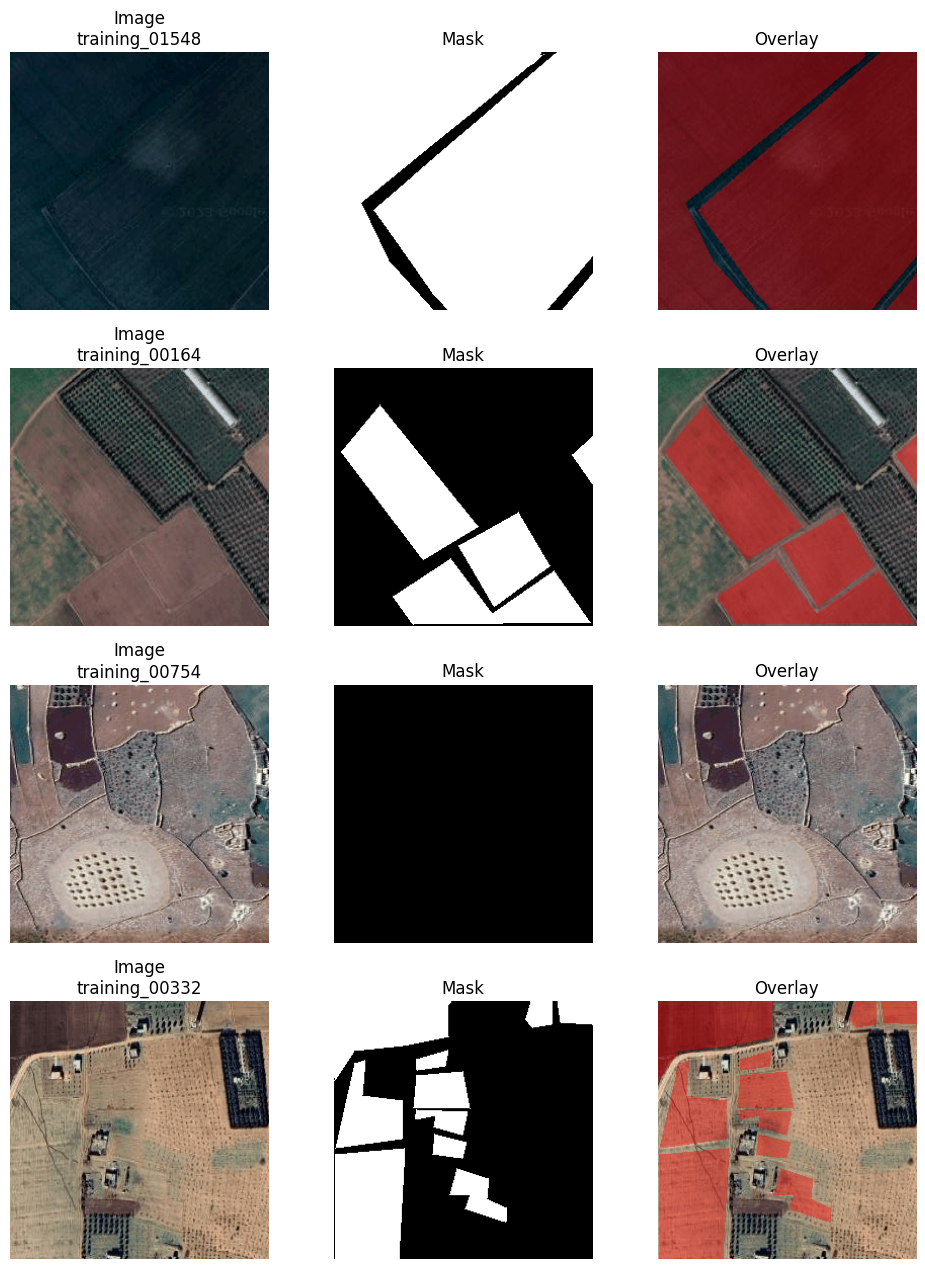

In [5]:
# Cell purpose: visualize a few augmented training samples.
# Why this matters:
# - We need to confirm that image and mask augmentations stay aligned.
# - Red overlay shows landing-site pixels on top of the image.
# - If this looks wrong, training metrics cannot be trusted.

IMAGENET_MEAN = np.array(segmentation_common.IMAGENET_MEAN, dtype=np.float32)
IMAGENET_STD = np.array(segmentation_common.IMAGENET_STD, dtype=np.float32)


def tensor_to_rgb(image_tensor: torch.Tensor) -> np.ndarray:
    image = image_tensor.detach().cpu().permute(1, 2, 0).numpy()
    image = (image * IMAGENET_STD) + IMAGENET_MEAN
    image = np.clip(image, 0.0, 1.0)
    return image


def overlay_mask(rgb_image: np.ndarray, mask: np.ndarray, alpha: float = 0.40) -> np.ndarray:
    overlay = rgb_image.copy()
    red = np.zeros_like(overlay)
    red[..., 0] = 1.0
    mask_bool = mask.astype(bool)
    overlay[mask_bool] = (
        (1 - alpha) * overlay[mask_bool]
        + alpha * red[mask_bool]
    )
    return np.clip(overlay, 0.0, 1.0)


images, masks, image_ids = next(iter(train_loader))
n_show = min(4, images.shape[0])

fig, axes = plt.subplots(n_show, 3, figsize=(10, 3.2 * n_show))
if n_show == 1:
    axes = np.expand_dims(axes, axis=0)

for row_index in range(n_show):
    rgb = tensor_to_rgb(images[row_index])
    mask = masks[row_index].cpu().numpy()

    axes[row_index, 0].imshow(rgb)
    axes[row_index, 0].set_title(f"Image\n{image_ids[row_index]}")
    axes[row_index, 0].axis("off")

    axes[row_index, 1].imshow(mask, cmap="gray", vmin=0, vmax=1)
    axes[row_index, 1].set_title("Mask")
    axes[row_index, 1].axis("off")

    axes[row_index, 2].imshow(overlay_mask(rgb, mask))
    axes[row_index, 2].set_title("Overlay")
    axes[row_index, 2].axis("off")

plt.tight_layout()
plt.show()


## 5. Loss, model, and metric functions

We use weighted cross-entropy from NB0's training-pixel distribution plus Dice loss. This helps with class imbalance while still optimizing region overlap.


In [6]:
# Cell purpose: define the loss function.
# How it works:
# - Weighted CrossEntropyLoss handles class imbalance using NB0's training-pixel statistics.
# - Dice loss helps optimize region overlap, which is important for segmentation.
# - Auxiliary loss is used because Torchvision DeepLabV3 can output an auxiliary prediction head during training.

distribution_path = NB0_OUTPUT_ROOT / "metadata" / "training_class_distribution.csv"
assert distribution_path.exists(), (
    "NB0 training_class_distribution.csv was not found."
)

class_distribution_df = pd.read_csv(distribution_path).sort_values("class_id")
display(class_distribution_df)

class_weights = torch.tensor(
    class_distribution_df["inverse_frequency_class_weight"].values,
    dtype=torch.float32,
    device=DEVICE,
)

print("Class weights:", class_weights.detach().cpu().tolist())

ce_loss = nn.CrossEntropyLoss(weight=class_weights)
DICE_LOSS_WEIGHT = 1.00
AUX_LOSS_WEIGHT = 0.40


def dice_loss_from_logits(
    logits: torch.Tensor,
    targets: torch.Tensor,
    epsilon: float = 1e-6,
) -> torch.Tensor:
    probabilities = torch.softmax(logits, dim=1)
    one_hot = F.one_hot(targets, num_classes=NUM_CLASSES)
    one_hot = one_hot.permute(0, 3, 1, 2).float()

    dims = (0, 2, 3)
    intersection = (probabilities * one_hot).sum(dim=dims)
    cardinality = (probabilities + one_hot).sum(dim=dims)
    dice = (2.0 * intersection + epsilon) / (cardinality + epsilon)

    return 1.0 - dice.mean()


def segmentation_loss(outputs: dict, targets: torch.Tensor) -> torch.Tensor:
    main_logits = outputs["out"]
    loss = ce_loss(main_logits, targets)
    loss = loss + DICE_LOSS_WEIGHT * dice_loss_from_logits(main_logits, targets)

    if "aux" in outputs and outputs["aux"] is not None:
        loss = loss + AUX_LOSS_WEIGHT * ce_loss(outputs["aux"], targets)

    return loss


def autocast_context():
    if DEVICE.type != "cuda":
        return nullcontext()
    try:
        return torch.amp.autocast("cuda", enabled=USE_AMP)
    except TypeError:
        return torch.cuda.amp.autocast(enabled=USE_AMP)


def make_grad_scaler():
    if DEVICE.type != "cuda":
        return torch.cuda.amp.GradScaler(enabled=False)
    try:
        return torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except TypeError:
        return torch.cuda.amp.GradScaler(enabled=USE_AMP)


,class_id,class_name,training_pixel_count,training_pixel_percent,inverse_frequency_class_weight
0,0,background,64478549,69.481962,0.719611
1,1,landing_site,28320427,30.518038,1.638375


Class weights: [0.7196112275123596, 1.6383752822875977]


In [7]:
# Cell purpose: create the DeepLabV3-ResNet50 model.
# How it works:
# - It first tries to load pretrained Torchvision weights.
# - If internet/pretrained download fails, it falls back to random initialization.
# - The final classifier layers are replaced so the model predicts exactly 2 classes: background and landing_site.

def create_deeplabv3_model(num_classes: int = 2) -> nn.Module:
    try:
        weights = DeepLabV3_ResNet50_Weights.DEFAULT
        model = deeplabv3_resnet50(weights=weights, aux_loss=True)
        print("Loaded Torchvision pretrained DeepLabV3 weights.")
    except Exception as error:
        print("Could not load pretrained weights.")
        print("Reason:", repr(error))
        print("Falling back to random initialization. For better results, enable internet in Kaggle.")
        model = deeplabv3_resnet50(
            weights=None,
            weights_backbone=None,
            aux_loss=True,
        )

    model.classifier = DeepLabHead(2048, num_classes)

    if model.aux_classifier is not None:
        model.aux_classifier = FCNHead(1024, num_classes)

    return model


model = create_deeplabv3_model(NUM_CLASSES).to(DEVICE)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print(f"Trainable parameters: {trainable_parameters:,}")


Downloading: "https://download.pytorch.org/models/deeplabv3_resnet50_coco-cd0a2569.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_resnet50_coco-cd0a2569.pth


100%|██████████| 161M/161M [00:00<00:00, 175MB/s]


Loaded Torchvision pretrained DeepLabV3 weights.
Trainable parameters: 41,994,308


In [8]:
# Cell purpose: define metric helpers and the evaluation loop.
# Metrics produced:
# - confusion matrix
# - mIoU and per-class IoU
# - overall pixel accuracy
# - mean pixel accuracy
# - Dice/F1
# The same functions are used for validation during training and final test evaluation.

def batch_confusion_matrix(
    predictions: torch.Tensor,
    targets: torch.Tensor,
    num_classes: int = NUM_CLASSES,
) -> torch.Tensor:
    predictions = predictions.detach().view(-1).cpu()
    targets = targets.detach().view(-1).cpu()

    valid = (targets >= 0) & (targets < num_classes)
    encoded = num_classes * targets[valid] + predictions[valid]

    return torch.bincount(
        encoded,
        minlength=num_classes ** 2,
    ).reshape(num_classes, num_classes)


def metrics_from_confusion_matrix(confusion: np.ndarray) -> dict:
    confusion = confusion.astype(np.float64)
    true_positive = np.diag(confusion)
    actual_pixels = confusion.sum(axis=1)
    predicted_pixels = confusion.sum(axis=0)
    union = actual_pixels + predicted_pixels - true_positive

    per_class_iou = np.divide(
        true_positive,
        union,
        out=np.zeros_like(true_positive),
        where=union > 0,
    )

    per_class_accuracy = np.divide(
        true_positive,
        actual_pixels,
        out=np.zeros_like(true_positive),
        where=actual_pixels > 0,
    )

    per_class_dice = np.divide(
        2 * true_positive,
        actual_pixels + predicted_pixels,
        out=np.zeros_like(true_positive),
        where=(actual_pixels + predicted_pixels) > 0,
    )

    overall_pixel_accuracy = (
        true_positive.sum() / confusion.sum()
        if confusion.sum() > 0
        else 0.0
    )

    return {
        "mean_iou": float(np.mean(per_class_iou)),
        "overall_pixel_accuracy": float(overall_pixel_accuracy),
        "mean_pixel_accuracy": float(np.mean(per_class_accuracy)),
        "mean_dice": float(np.mean(per_class_dice)),
        "per_class_iou": {
            CLASS_ID_TO_NAME[index]: float(value)
            for index, value in enumerate(per_class_iou)
        },
        "per_class_accuracy": {
            CLASS_ID_TO_NAME[index]: float(value)
            for index, value in enumerate(per_class_accuracy)
        },
        "per_class_dice": {
            CLASS_ID_TO_NAME[index]: float(value)
            for index, value in enumerate(per_class_dice)
        },
    }


@torch.no_grad()
def evaluate_model(
    model: nn.Module,
    data_loader: DataLoader,
    split_name: str,
) -> tuple[dict, float, pd.DataFrame, np.ndarray]:
    model.eval()

    total_loss = 0.0
    total_samples = 0
    confusion = torch.zeros(
        NUM_CLASSES,
        NUM_CLASSES,
        dtype=torch.int64,
    )

    per_image_records = []

    for images, masks, image_ids in tqdm(data_loader, desc=f"Evaluate {split_name}"):
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        with autocast_context():
            outputs = model(images)
            loss = segmentation_loss(outputs, masks)

        logits = outputs["out"]
        predictions = torch.argmax(logits, dim=1)

        batch_size = images.shape[0]
        total_loss += float(loss.item()) * batch_size
        total_samples += batch_size

        confusion += batch_confusion_matrix(predictions, masks)

        for index, image_id in enumerate(image_ids):
            image_confusion = batch_confusion_matrix(
                predictions[index],
                masks[index],
            ).numpy()

            image_metrics = metrics_from_confusion_matrix(image_confusion)
            per_image_records.append(
                {
                    "image_id": image_id,
                    "split": split_name,
                    "mean_iou": image_metrics["mean_iou"],
                    "landing_site_iou": image_metrics["per_class_iou"]["landing_site"],
                    "background_iou": image_metrics["per_class_iou"]["background"],
                    "mean_dice": image_metrics["mean_dice"],
                }
            )

    confusion_np = confusion.numpy()
    metrics = metrics_from_confusion_matrix(confusion_np)
    average_loss = total_loss / max(total_samples, 1)
    per_image_df = pd.DataFrame(per_image_records)

    return metrics, average_loss, per_image_df, confusion_np


## 6. Train DeepLabV3

This test copy trains for **5 epochs** so we can check whether the full pipeline works. For the final submitted NB1 run, change `"epochs": 5` back to `"epochs": 50`.


In [9]:
# Cell purpose: train DeepLabV3.
# Training flow:
# 1. Train one epoch on train_loader.
# 2. Evaluate on val_loader.
# 3. Save the best checkpoint based on validation mIoU.

CONFIG = {
    "notebook": "NB1",
    "model": "DeepLabV3-ResNet50",
    "seed": SEED,
    "image_size": IMAGE_SIZE,
    "num_classes": NUM_CLASSES,
    "batch_size": BATCH_SIZE,
    "epochs": 50,  # Test run epochs": 50
    "optimizer": "AdamW",
    "learning_rate": 1e-4,
    "weight_decay": 1e-4,
    "loss": "weighted_cross_entropy + 0.5*dice + 0.4*aux_ce",
    "split_file": str(SPLIT_FILE),
    "nb0_output_root": str(NB0_OUTPUT_ROOT),
    "raw_dataset_root": str(DATA_ROOT),
    "saved_at": datetime.now(timezone.utc).isoformat(),
}

# AdamW updates model weights. Weight decay adds light regularization.
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=CONFIG["learning_rate"],
    weight_decay=CONFIG["weight_decay"],
)

# The scheduler slowly adjusts the learning rate across epochs.
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=CONFIG["epochs"],
)

# GradScaler supports mixed precision training on GPU.
scaler = make_grad_scaler()


# This function performs one full pass over the training dataset.
def train_one_epoch(
    model: nn.Module,
    data_loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    epoch: int,
) -> float:
    model.train()
    running_loss = 0.0
    total_samples = 0

    progress = tqdm(data_loader, desc=f"Train epoch {epoch:02d}")

    for images, masks, _ in progress:
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        # Clear old gradients before calculating new ones.
        optimizer.zero_grad(set_to_none=True)

        with autocast_context():
            outputs = model(images)
            loss = segmentation_loss(outputs, masks)

        # Backpropagation: calculate gradients from the loss.
        scaler.scale(loss).backward()
        # Optimizer step: update model weights.
        scaler.step(optimizer)
        scaler.update()

        batch_size = images.shape[0]
        running_loss += float(loss.item()) * batch_size
        total_samples += batch_size
        progress.set_postfix(loss=running_loss / max(total_samples, 1))

    return running_loss / max(total_samples, 1)


history = []
best_val_miou = -1.0
best_epoch = 0
best_checkpoint_path = OUTPUT_ROOT / "deeplabv3_best.pth"

start_time = time.time()

for epoch in range(1, CONFIG["epochs"] + 1):
    train_loss = train_one_epoch(model, train_loader, optimizer, epoch)
    val_metrics, val_loss, _, _ = evaluate_model(model, val_loader, "val")
    scheduler.step()

    current_lr = optimizer.param_groups[0]["lr"]
    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_mIoU": val_metrics["mean_iou"],
        "val_overall_pixel_accuracy": val_metrics["overall_pixel_accuracy"],
        "val_mean_dice": val_metrics["mean_dice"],
        "learning_rate": current_lr,
    }
    history.append(row)

    print(
        f"Epoch {epoch:02d}/{CONFIG['epochs']} | "
        f"train loss {train_loss:.4f} | "
        f"val loss {val_loss:.4f} | "
        f"val mIoU {val_metrics['mean_iou']:.4f} | "
        f"val Dice {val_metrics['mean_dice']:.4f}"
    )

    # Save the best model so far using validation mIoU.
    if val_metrics["mean_iou"] > best_val_miou:
        best_val_miou = val_metrics["mean_iou"]
        best_epoch = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "config": CONFIG,
                "val_metrics": val_metrics,
            },
            best_checkpoint_path,
        )

elapsed_minutes = (time.time() - start_time) / 60
print(f"Training finished in {elapsed_minutes:.2f} minutes.")
print(f"Best validation mIoU: {best_val_miou:.4f} at epoch {best_epoch}.")
print("Best checkpoint:", best_checkpoint_path)

history_df = pd.DataFrame(history)
history_df.to_csv(OUTPUT_ROOT / "deeplabv3_training_history.csv", index=False)
display(history_df.tail())


Train epoch 01:   0%|          | 0/89 [00:00<?, ?it/s]

Evaluate val:   0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01/50 | train loss 0.7986 | val loss 0.5623 | val mIoU 0.7971 | val Dice 0.8846


Train epoch 02:   0%|          | 0/89 [00:00<?, ?it/s]

Evaluate val:   0%|          | 0/20 [00:00<?, ?it/s]

Epoch 02/50 | train loss 0.5616 | val loss 0.4588 | val mIoU 0.7871 | val Dice 0.8791


... (141 outputs left out)

Train epoch 50:   0%|          | 0/89 [00:00<?, ?it/s]

Evaluate val:   0%|          | 0/20 [00:00<?, ?it/s]

Epoch 50/50 | train loss 0.1250 | val loss 0.3067 | val mIoU 0.8821 | val Dice 0.9367
Training finished in 35.41 minutes.
Best validation mIoU: 0.8835 at epoch 48.
Best checkpoint: /kaggle/working/NB1_outputs/deeplabv3_best.pth


,epoch,train_loss,val_loss,val_mIoU,val_overall_pixel_accuracy,val_mean_dice,learning_rate
45,46,0.126355,0.296392,0.883087,0.949066,0.937214,1.570842e-06
46,47,0.129578,0.310804,0.881918,0.948720,0.936527,8.856375e-07
47,48,0.122000,0.303197,0.883478,0.949323,0.937435,3.942649e-07
48,49,0.123779,0.318762,0.882101,0.948891,0.936627,9.866358e-08
49,50,0.124954,0.306727,0.882135,0.948603,0.936666,0.000000e+00


## 7. Training curves


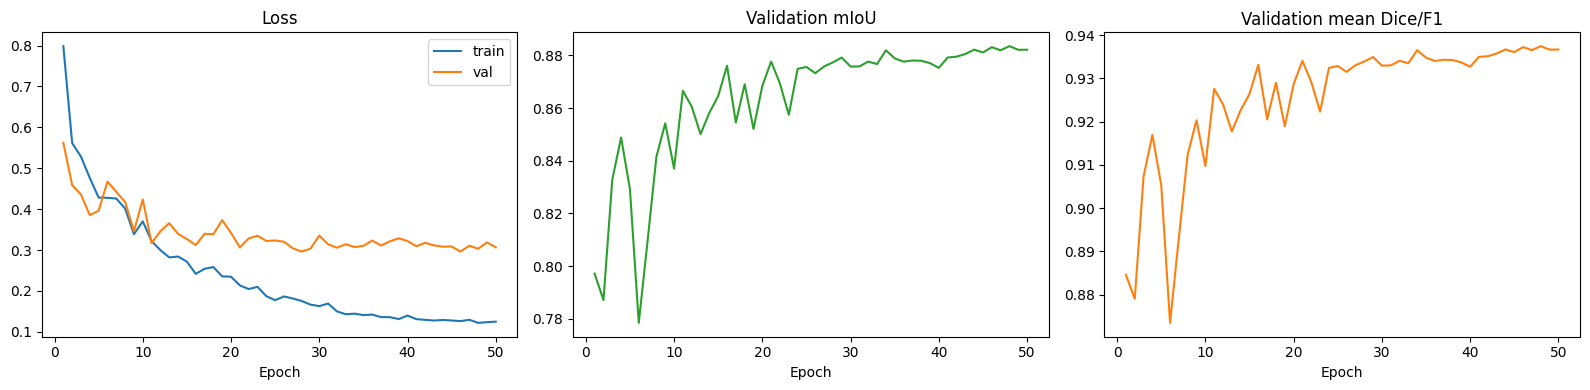

In [10]:
# Cell purpose: plot training curves.
# These plots help you understand whether the model is learning:
# - train/validation loss should usually decrease
# - validation mIoU and Dice/F1 should usually improve

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(history_df["epoch"], history_df["train_loss"], label="train")
axes[0].plot(history_df["epoch"], history_df["val_loss"], label="val")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history_df["epoch"], history_df["val_mIoU"], color="tab:green")
axes[1].set_title("Validation mIoU")
axes[1].set_xlabel("Epoch")

axes[2].plot(history_df["epoch"], history_df["val_mean_dice"], color="tab:orange")
axes[2].set_title("Validation mean Dice/F1")
axes[2].set_xlabel("Epoch")

plt.tight_layout()
plt.savefig(OUTPUT_ROOT / "deeplabv3_training_curves.png", dpi=160)
plt.show()


## 8. Test-set evaluation

The final test metrics are computed using the best validation checkpoint.


In [11]:
# Cell purpose: evaluate the best checkpoint on the held-out test set.
# Important:
# - The test set is only used after training.
# - Metrics from this cell are the main NB1 results for the report and NB3 comparison.

checkpoint = torch.load(best_checkpoint_path, map_location=DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE)

test_metrics, test_loss, test_per_image_df, test_confusion = evaluate_model(
    model,
    test_loader,
    "test",
)

print("Test loss:", test_loss)
print(json.dumps(test_metrics, indent=2))

per_class_metrics_df = pd.DataFrame(
    [
        {
            "class_id": class_id,
            "class_name": CLASS_ID_TO_NAME[class_id],
            "iou": test_metrics["per_class_iou"][CLASS_ID_TO_NAME[class_id]],
            "pixel_accuracy": test_metrics["per_class_accuracy"][CLASS_ID_TO_NAME[class_id]],
            "dice_f1": test_metrics["per_class_dice"][CLASS_ID_TO_NAME[class_id]],
        }
        for class_id in range(NUM_CLASSES)
    ]
)

confusion_df = pd.DataFrame(
    test_confusion,
    index=[f"true_{CLASS_ID_TO_NAME[i]}" for i in range(NUM_CLASSES)],
    columns=[f"pred_{CLASS_ID_TO_NAME[i]}" for i in range(NUM_CLASSES)],
)

display(Markdown("### Overall test metrics"))
display(pd.DataFrame([{
    "mIoU": test_metrics["mean_iou"],
    "overall_pixel_accuracy": test_metrics["overall_pixel_accuracy"],
    "mean_pixel_accuracy": test_metrics["mean_pixel_accuracy"],
    "mean_dice_f1": test_metrics["mean_dice"],
}]))

display(Markdown("### Per-class metrics"))
display(per_class_metrics_df)

display(Markdown("### Pixel-level confusion matrix"))
display(confusion_df)


Evaluate test:   0%|          | 0/23 [00:00<?, ?it/s]

Test loss: 0.6501840445730421
{
  "mean_iou": 0.8219835756399225,
  "overall_pixel_accuracy": 0.9147978040907118,
  "mean_pixel_accuracy": 0.9013388854171767,
  "mean_dice": 0.9010582406229025,
  "per_class_iou": {
    "background": 0.8831124026957672,
    "landing_site": 0.7608547485840779
  },
  "per_class_accuracy": {
    "background": 0.9373780891513903,
    "landing_site": 0.8652996816829631
  },
  "per_class_dice": {
    "background": 0.937928507540547,
    "landing_site": 0.864187973705258
  }
}


### Overall test metrics

,mIoU,overall_pixel_accuracy,mean_pixel_accuracy,mean_dice_f1
0,0.821984,0.914798,0.901339,0.901058


### Per-class metrics

,class_id,class_name,iou,pixel_accuracy,dice_f1
0,0,background,0.883112,0.937378,0.937929
1,1,landing_site,0.760855,0.865300,0.864188


### Pixel-level confusion matrix

,pred_background,pred_landing_site
true_background,15187307,1014594
true_landing_site,995578,6395481


In [12]:
# Cell purpose: save test metrics and configuration files.
# NB3 will use these saved files to compare DeepLabV3 against SegFormer-B0 and YOLO-sem.
# The JSON file is the most important summary output.

metrics_payload = {
    "notebook": "NB1",
    "model": "DeepLabV3-ResNet50",
    "dataset": "Moroccan Landing Site Segmentation V2",
    "split_source": str(SPLIT_FILE),
    "nb0_output_root": str(NB0_OUTPUT_ROOT),
    "best_epoch": int(best_epoch),
    "trained_epochs": int(CONFIG["epochs"]),
    "test_loss": float(test_loss),
    "metrics": test_metrics,
    "confusion_matrix": test_confusion.astype(int).tolist(),
    "class_names": CLASS_ID_TO_NAME,
    "config": CONFIG,
    "saved_at": datetime.now(timezone.utc).isoformat()
}

with (OUTPUT_ROOT / "deeplabv3_metrics.json").open("w", encoding="utf-8") as file:
    json.dump(metrics_payload, file, indent=2)

per_class_metrics_df.to_csv(
    OUTPUT_ROOT / "deeplabv3_per_class_metrics.csv",
    index=False,
)

test_per_image_df.to_csv(
    OUTPUT_ROOT / "deeplabv3_per_image_test_metrics.csv",
    index=False,
)

confusion_df.to_csv(
    OUTPUT_ROOT / "deeplabv3_confusion_matrix.csv",
)

with (OUTPUT_ROOT / "deeplabv3_config.json").open("w", encoding="utf-8") as file:
    json.dump(CONFIG, file, indent=2)

print("Saved NB1 metrics and CSV outputs to:", OUTPUT_ROOT)


Saved NB1 metrics and CSV outputs to: /kaggle/working/NB1_outputs


## 9. Error analysis

We inspect the worst test images by mIoU and summarize the dominant confusion pattern.


,image_id,split,mean_iou,landing_site_iou,background_iou,mean_dice
0,testing_00247,test,0.034590,0.039337,0.029842,0.066825
1,testing_00005,test,0.209603,0.250207,0.168999,0.344699
2,testing_00172,test,0.264381,0.000000,0.528763,0.345876
3,testing_00161,test,0.266193,0.291198,0.241188,0.419846
4,testing_00124,test,0.301773,0.000000,0.603546,0.376382


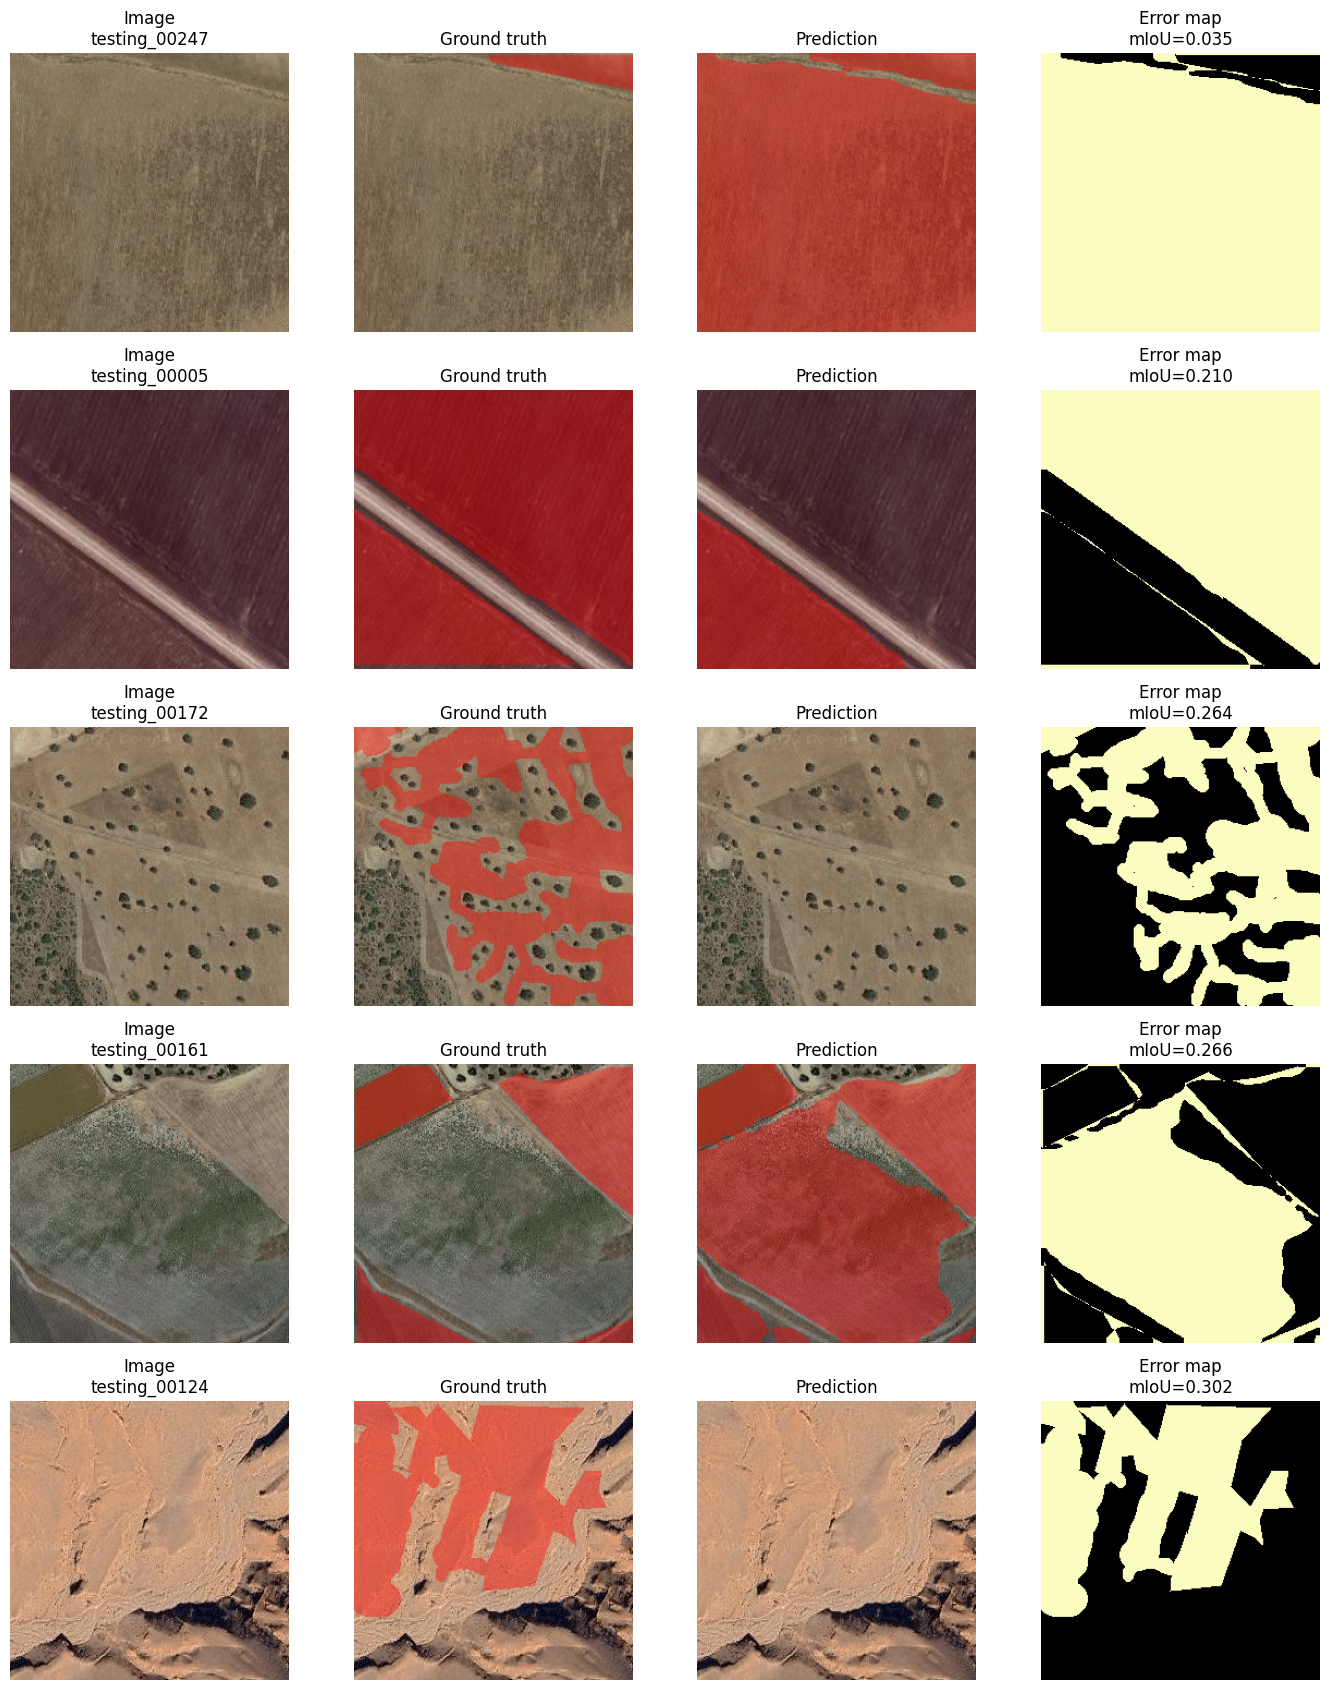

In [13]:
# Cell purpose: show the worst DeepLabV3 test predictions.
# How it works:
# - Sort test images by lowest mIoU.
# - Display original image, ground truth, prediction, and error map.
# This supports the assignment's error-analysis requirement.

worst_df = (
    test_per_image_df
    .sort_values(["mean_iou", "landing_site_iou"], ascending=True)
    .head(5)
    .reset_index(drop=True)
)

display(worst_df)


def predict_row(row: pd.Series) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    image_path = DATA_ROOT / row["image_relpath"]
    mask_path = NB0_OUTPUT_ROOT / row["encoded_mask_relpath"]

    with Image.open(image_path) as image_file:
        rgb_uint8 = np.asarray(image_file.convert("RGB"), dtype=np.uint8)

    mask = load_mask(mask_path)

    transformed = eval_transform(image=rgb_uint8, mask=mask)
    image_tensor = transformed["image"].unsqueeze(0).to(DEVICE)

    model.eval()
    with torch.no_grad():
        logits = model(image_tensor)["out"]
        prediction = torch.argmax(logits, dim=1)[0].cpu().numpy().astype(np.uint8)

    return rgb_uint8 / 255.0, mask.astype(np.uint8), prediction


fig, axes = plt.subplots(len(worst_df), 4, figsize=(14, 3.4 * len(worst_df)))
if len(worst_df) == 1:
    axes = np.expand_dims(axes, axis=0)

for row_index, row in worst_df.iterrows():
    manifest_row = test_df[test_df["image_id"] == row["image_id"]].iloc[0]
    rgb, truth, prediction = predict_row(manifest_row)
    error_map = (truth != prediction).astype(np.uint8)

    axes[row_index, 0].imshow(rgb)
    axes[row_index, 0].set_title(f"Image\n{row['image_id']}")
    axes[row_index, 0].axis("off")

    axes[row_index, 1].imshow(overlay_mask(rgb, truth))
    axes[row_index, 1].set_title("Ground truth")
    axes[row_index, 1].axis("off")

    axes[row_index, 2].imshow(overlay_mask(rgb, prediction))
    axes[row_index, 2].set_title("Prediction")
    axes[row_index, 2].axis("off")

    axes[row_index, 3].imshow(error_map, cmap="magma", vmin=0, vmax=1)
    axes[row_index, 3].set_title(f"Error map\nmIoU={row['mean_iou']:.3f}")
    axes[row_index, 3].axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_ROOT / "deeplabv3_worst_examples.png", dpi=160)
plt.show()


In [14]:
# Cell purpose: write a short automatic error-analysis summary.
# It compares false positives and false negatives in the pixel-level confusion matrix.
# You can use this text as a starting point in your final report/viva explanation.

false_positive_pixels = int(test_confusion[0, 1])
false_negative_pixels = int(test_confusion[1, 0])

if false_negative_pixels > false_positive_pixels:
    dominant_error = (
        "The dominant error is false negatives: some landing-site pixels "
        "are predicted as background."
    )
elif false_positive_pixels > false_negative_pixels:
    dominant_error = (
        "The dominant error is false positives: some background pixels "
        "are predicted as landing site."
    )
else:
    dominant_error = (
        "False positives and false negatives are approximately balanced."
    )

error_analysis_text = f'''
### DeepLabV3 error analysis

**Worst test examples:** saved in `deeplabv3_worst_examples.png`.

**Main pixel confusion:**

- Background -> landing site false positives: `{false_positive_pixels:,}`
- Landing site -> background false negatives: `{false_negative_pixels:,}`

{dominant_error}

**Likely failure modes to discuss in the report:**

1. Boundary uncertainty: DeepLabV3 may blur landing-site edges.
2. Class imbalance: background is much more common than landing-site pixels.
3. Visual ambiguity: bright roads, open terrain, or runway-like regions can resemble landing-site areas.
4. Small or thin landing-site regions are easier to miss than large compact regions.
'''

error_analysis_text = textwrap.dedent(error_analysis_text).strip()

with (OUTPUT_ROOT / "deeplabv3_error_analysis.md").open("w", encoding="utf-8") as file:
    file.write(error_analysis_text + "\n")

display(Markdown(error_analysis_text))


### DeepLabV3 error analysis

**Worst test examples:** saved in `deeplabv3_worst_examples.png`.

**Main pixel confusion:**

- Background -> landing site false positives: `1,014,594`
- Landing site -> background false negatives: `995,578`

The dominant error is false positives: some background pixels are predicted as landing site.

**Likely failure modes to discuss in the report:**

1. Boundary uncertainty: DeepLabV3 may blur landing-site edges.
2. Class imbalance: background is much more common than landing-site pixels.
3. Visual ambiguity: bright roads, open terrain, or runway-like regions can resemble landing-site areas.
4. Small or thin landing-site regions are easier to miss than large compact regions.

## 10. Save fixed qualitative comparison predictions for NB3

NB0 selected fixed test image IDs. NB1 saves predictions for those same images so NB3 can compare DeepLabV3, SegFormer-B0, and YOLO-sem fairly.


In [15]:
# Cell purpose: save predictions for NB3's fixed comparison images.
# Why:
# - NB0 selected the same test sample IDs for all model notebooks.
# - NB1 saves DeepLabV3 predictions for those IDs so NB3 can make a fair qualitative comparison.

comparison_file = NB0_OUTPUT_ROOT / "comparison_sample_ids.json"
comparison_dir = OUTPUT_ROOT / "comparison_predictions"
comparison_dir.mkdir(parents=True, exist_ok=True)

if comparison_file.exists():
    with comparison_file.open("r", encoding="utf-8") as file:
        comparison_ids = json.load(file)["sample_ids"]
else:
    comparison_ids = (
        test_per_image_df
        .sort_values("mean_iou")
        .head(5)["image_id"]
        .tolist()
    )

saved_prediction_rows = []

for image_id in comparison_ids:
    row = test_df[test_df["image_id"] == image_id].iloc[0]
    rgb, truth, prediction = predict_row(row)

    pred_path = comparison_dir / f"{image_id}_deeplabv3_pred.png"
    overlay_path = comparison_dir / f"{image_id}_deeplabv3_overlay.png"

    Image.fromarray(prediction.astype(np.uint8)).save(pred_path)

    overlay_uint8 = (overlay_mask(rgb, prediction) * 255).astype(np.uint8)
    Image.fromarray(overlay_uint8).save(overlay_path)

    saved_prediction_rows.append(
        {
            "image_id": image_id,
            "prediction_path": str(pred_path),
            "overlay_path": str(overlay_path),
        }
    )

comparison_predictions_df = pd.DataFrame(saved_prediction_rows)
comparison_predictions_df.to_csv(
    OUTPUT_ROOT / "deeplabv3_comparison_predictions.csv",
    index=False,
)

display(comparison_predictions_df)
print("Saved comparison predictions for NB3.")


,image_id,prediction_path,overlay_path
0,testing_00004,/kaggle/working/NB1_outputs/comparison_predict...,/kaggle/working/NB1_outputs/comparison_predict...
1,testing_00086,/kaggle/working/NB1_outputs/comparison_predict...,/kaggle/working/NB1_outputs/comparison_predict...
2,testing_00058,/kaggle/working/NB1_outputs/comparison_predict...,/kaggle/working/NB1_outputs/comparison_predict...
3,testing_00006,/kaggle/working/NB1_outputs/comparison_predict...,/kaggle/working/NB1_outputs/comparison_predict...
4,testing_00352,/kaggle/working/NB1_outputs/comparison_predict...,/kaggle/working/NB1_outputs/comparison_predict...


Saved comparison predictions for NB3.


## 11. Final NB1 output check


In [16]:
# Cell purpose: final output check.
# It confirms that all expected NB1 result files were created before you submit or share the notebook output.

required_outputs = [
    OUTPUT_ROOT / "deeplabv3_best.pth",
    OUTPUT_ROOT / "deeplabv3_metrics.json",
    OUTPUT_ROOT / "deeplabv3_per_class_metrics.csv",
    OUTPUT_ROOT / "deeplabv3_per_image_test_metrics.csv",
    OUTPUT_ROOT / "deeplabv3_confusion_matrix.csv",
    OUTPUT_ROOT / "deeplabv3_training_history.csv",
    OUTPUT_ROOT / "deeplabv3_error_analysis.md",
    OUTPUT_ROOT / "deeplabv3_comparison_predictions.csv",
]

for output_path in required_outputs:
    assert output_path.exists(), f"Missing output: {output_path}"

print("NB1_outputs/")
for path in sorted(OUTPUT_ROOT.rglob("*")):
    print(" -", path.relative_to(OUTPUT_ROOT))

print("\nNB1 completed successfully.")


NB1_outputs/
 - comparison_predictions
 - comparison_predictions/testing_00004_deeplabv3_overlay.png
 - comparison_predictions/testing_00004_deeplabv3_pred.png
 - comparison_predictions/testing_00006_deeplabv3_overlay.png
 - comparison_predictions/testing_00006_deeplabv3_pred.png
 - comparison_predictions/testing_00058_deeplabv3_overlay.png
 - comparison_predictions/testing_00058_deeplabv3_pred.png
 - comparison_predictions/testing_00086_deeplabv3_overlay.png
 - comparison_predictions/testing_00086_deeplabv3_pred.png
 - comparison_predictions/testing_00352_deeplabv3_overlay.png
 - comparison_predictions/testing_00352_deeplabv3_pred.png
 - deeplabv3_best.pth
 - deeplabv3_comparison_predictions.csv
 - deeplabv3_config.json
 - deeplabv3_confusion_matrix.csv
 - deeplabv3_error_analysis.md
 - deeplabv3_metrics.json
 - deeplabv3_per_class_metrics.csv
 - deeplabv3_per_image_test_metrics.csv
 - deeplabv3_training_curves.png
 - deeplabv3_training_history.csv
 - deeplabv3_worst_examples.png

NB1